# Video Game Sales Prediction on Steam Data
## Notebook 4 — Modification 1: Excluding the Most Popular Games

**Motivation.** The baseline (Notebook 3) found that a small number of very popular games dominate
both model fitting and evaluation: the 20 test games with at least 10 million owners, 0.13% of the
test set, caused 76–96% of each model's squared error, and every model scored below zero R² once
they were removed from the test set (Section 7.4).

**Purpose of this modification.** To measure how the results change when the most popular games
are excluded. All other choices are kept identical to the baseline (the same 42 features, the same
default models, the same random train/test split and the same 5-fold cross-validation), so that
any difference can be attributed to the exclusion alone.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, GREEN, ORANGE, RED, GREY = "#4C72B0", "#55A868", "#DD8452", "#C44E52", "#8C8C8C"
MODEL_ORDER = ["Baseline (mean)", "Linear Regression", "Decision Tree", "Random Forest"]
MODEL_COLORS = dict(zip(MODEL_ORDER, [GREY, BLUE, ORANGE, GREEN]))
RANDOM_STATE = 42


def range_label(text):
    def short(n):
        n = int(n)
        if n >= 1_000_000:
            return f"{n // 1_000_000}M"
        return f"{n // 1000}k" if n >= 1000 else str(n)
    lo, hi = text.split(" - ")
    return f"{short(lo)}–{short(hi)}"


FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")

data = pd.read_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), parse_dates=["release_dt"])
with open(os.path.join(DATA_DIR, "features.json")) as f:
    spec = json.load(f)
TARGET = spec["target"]
FEATURES = spec["numeric"] + spec["genres"] + spec["categories"]

MODELS = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
}


def compute_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE (%)": 100 * np.mean(np.abs(y_pred - y_true) / y_true),
        "R2": r2_score(y_true, y_pred),
    }


print(f"{len(data):,} games | {len(FEATURES)} features | target: {TARGET}")

76,727 games | 42 features | target: owners_millions


---
# 9. Modification 1: Excluding the Most Popular Games

## 9.1 Rationale and limitation

**Rationale.** Least-squares models and squared-error metrics weight each error by its square. A
single game with 150 million owners that is predicted at 1 million contributes as much squared
error as more than 200 million typical games predicted 0.01 million too high. Excluding the most
popular games tests whether the baseline's poor performance is caused by these few games or
reflects a general lack of predictive signal in the features.

**Limitation.** Excluding games by their owner count changes the population the model describes:
the resulting models apply only to games that sell below the chosen threshold. Because a game's
popularity is not known before release, this exclusion cannot be applied when forecasting a new
game. The modification is therefore a **diagnostic**, not a deployable model. The excluded games
are also the most commercially important ones, so a model trained without them cannot identify
future blockbusters.

## 9.2 Definition of "popular"

There is no single accepted threshold, so three levels are compared with the baseline. A game is
excluded when its estimated owner range starts at or above the threshold.

In [2]:
THRESHOLDS = [
    ("All games (baseline)", None),
    ("Excluding games with 10M+ owners", 10.0),
    ("Excluding games with 1M+ owners", 1.0),
    ("Excluding games with 100k+ owners", 0.1),
]
total_owners = data[TARGET].sum()
scen_rows = []
for label, thr in THRESHOLDS:
    keep = data[TARGET] < thr if thr else pd.Series(True, index=data.index)
    kept = data.loc[keep, TARGET]
    scen_rows.append({
        "Scenario": label,
        "Games excluded": int((~keep).sum()),
        "Share of games excluded": (~keep).mean(),
        "Share of all owners excluded": 1 - kept.sum() / total_owners,
        "Games kept": int(keep.sum()),
        "Max owners kept (M)": kept.max(),
        "Target skewness": kept.skew(),
    })
scenarios = pd.DataFrame(scen_rows).set_index("Scenario")
scenarios.to_csv(os.path.join(TAB_DIR, "table11_popular_game_scenarios.csv"))
scenarios.style.format({"Games excluded": "{:,}", "Share of games excluded": "{:.2%}",
                        "Share of all owners excluded": "{:.1%}", "Games kept": "{:,}",
                        "Max owners kept (M)": "{:.3f}", "Target skewness": "{:.1f}"}) \
    .set_caption("Table 11. Scenarios for excluding popular games")

,Games excluded,Share of games excluded,Share of all owners excluded,Games kept,Max owners kept (M),Target skewness
Scenario,,,,,,
All games (baseline),0,0.00%,0.0%,"76,727",150.000,59.8
Excluding games with 10M+ owners,86,0.11%,29.8%,"76,641",7.500,11.7
Excluding games with 1M+ owners,"1,287",1.68%,64.0%,"75,440",0.750,4.7
Excluding games with 100k+ owners,"8,194",10.68%,87.0%,"68,533",0.075,2.3


**Observations.** The 86 games with 10 million owners or more are only 0.11% of all games but hold 29.8% of all owners; excluding them reduces the skewness of the target from 59.8 to 11.7. Excluding games with 1 million owners or more removes 1.7% of games and 64% of all owners (skewness 4.7). Excluding games with 100,000 owners or more removes 10.7% of games and 87% of all owners, leaving only the three lowest owner ranges (up to 75,000 owners, skewness 2.3). The target remains right-skewed in every scenario.

## 9.3 Experimental setup

- **Same split.** The data are divided into the same training (80%) and test (20%) sets as in the
  baseline (`random_state = 42`). Popular games are then removed from **both** sets, so each
  scenario's models are trained and evaluated on the same population.
- **Same models and settings.** Baseline (mean), Linear Regression, Decision Tree and Random
  Forest with scikit-learn default settings.
- **Same evaluation.** 5-fold cross-validation on the training set, followed by a single evaluation
  on the test set, with the five metrics of the parent paper.

In [3]:
train_all, test_all = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)
cv_rows, test_rows, fitted = [], [], {}

for label, thr in THRESHOLDS:
    tr = (train_all[train_all[TARGET] < thr] if thr else train_all).reset_index(drop=True)
    te = (test_all[test_all[TARGET] < thr] if thr else test_all).reset_index(drop=True)
    folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(tr))
    for name, model in MODELS.items():
        fold_metrics = []
        for f_tr, f_va in folds:
            m = clone(model).fit(tr.loc[f_tr, FEATURES], tr.loc[f_tr, TARGET])
            fold_metrics.append(compute_metrics(tr.loc[f_va, TARGET], m.predict(tr.loc[f_va, FEATURES])))
        fm = pd.DataFrame(fold_metrics)
        cv_rows.append({"Scenario": label, "Model": name,
                        **{f"{k} mean": v for k, v in fm.mean().items()},
                        **{f"{k} SD": v for k, v in fm.std().items()}})
        final = clone(model).fit(tr[FEATURES], tr[TARGET])
        fitted[(label, name)] = final
        pred = final.predict(te[FEATURES])
        test_rows.append({"Scenario": label, "Model": name, "Training games": len(tr), "Test games": len(te),
                          "Training R2": r2_score(tr[TARGET], final.predict(tr[FEATURES])),
                          **compute_metrics(te[TARGET], pred)})
    print(f"{label}: {len(tr):,} training / {len(te):,} test games done")

cv_table = pd.DataFrame(cv_rows)
test_table = pd.DataFrame(test_rows)
cv_table.to_csv(os.path.join(TAB_DIR, "table12_popular_cv.csv"), index=False)
test_table.to_csv(os.path.join(TAB_DIR, "table13_popular_test.csv"), index=False)

All games (baseline): 61,381 training / 15,346 test games done


Excluding games with 10M+ owners: 61,315 training / 15,326 test games done


Excluding games with 1M+ owners: 60,349 training / 15,091 test games done


Excluding games with 100k+ owners: 54,810 training / 13,723 test games done


## 9.4 Cross-validation results

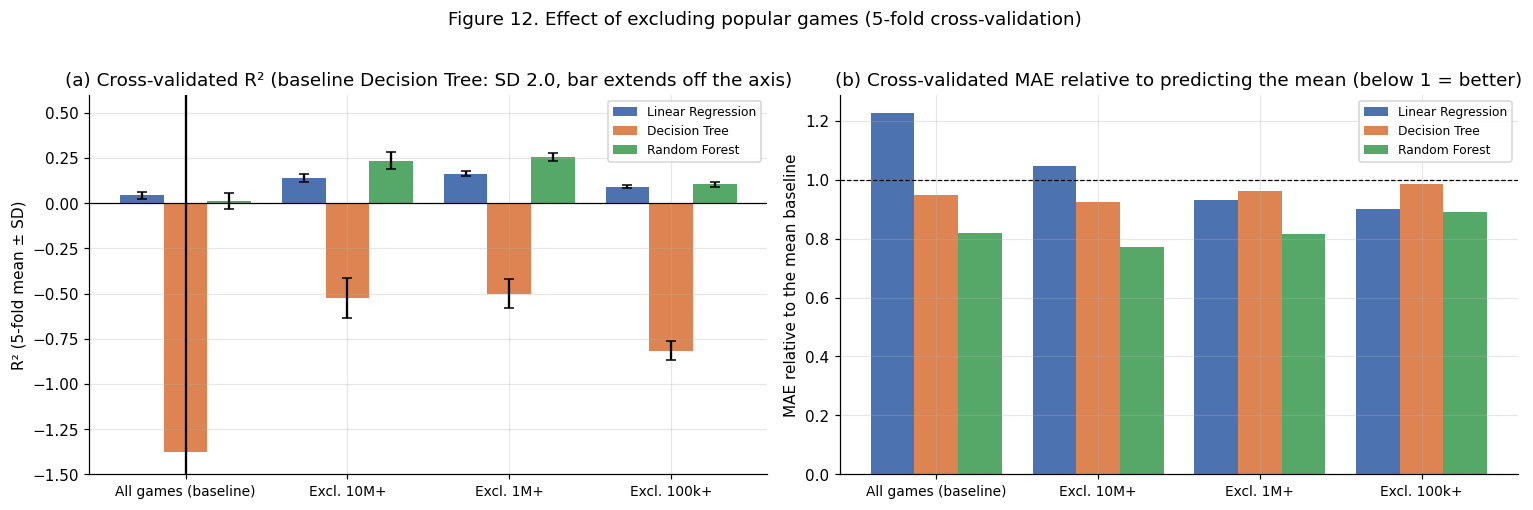

Model,Baseline (mean),Linear Regression,Decision Tree,Random Forest
Scenario,,,,
All games (baseline),-0.000 ± 0.000,0.044 ± 0.019,-1.376 ± 2.005,0.013 ± 0.044
Excluding games with 10M+ owners,-0.000 ± 0.000,0.139 ± 0.020,-0.522 ± 0.111,0.234 ± 0.047
Excluding games with 1M+ owners,-0.000 ± 0.000,0.164 ± 0.012,-0.501 ± 0.079,0.255 ± 0.025
Excluding games with 100k+ owners,-0.000 ± 0.000,0.090 ± 0.008,-0.816 ± 0.052,0.103 ± 0.013


In [4]:
scen_order = [s for s, _ in THRESHOLDS]
r2_view = cv_table.assign(value=lambda t: t["R2 mean"].map("{:.3f}".format) + " ± " + t["R2 SD"].map("{:.3f}".format)) \
    .pivot(index="Scenario", columns="Model", values="value").loc[scen_order, MODEL_ORDER]
mae_view = cv_table.pivot(index="Scenario", columns="Model", values="MAE mean").loc[scen_order, MODEL_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(len(scen_order))
w = 0.27
for i, m in enumerate(MODEL_ORDER[1:]):
    sub = cv_table[cv_table["Model"] == m].set_index("Scenario").loc[scen_order]
    axes[0].bar(x + (i - 1) * w, sub["R2 mean"], w, yerr=sub["R2 SD"], capsize=3, color=MODEL_COLORS[m], label=m)
    rel_mae = sub["MAE mean"] / mae_view["Baseline (mean)"]
    axes[1].bar(x + (i - 1) * w, rel_mae, w, color=MODEL_COLORS[m], label=m)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_ylim(-1.5, 0.6)
axes[0].set_ylabel("R² (5-fold mean ± SD)")
axes[0].set_title("(a) Cross-validated R² (baseline Decision Tree: SD 2.0, bar extends off the axis)")
axes[1].axhline(1, color="black", lw=0.8, ls="--")
axes[1].set_ylabel("MAE relative to the mean baseline")
axes[1].set_title("(b) Cross-validated MAE relative to predicting the mean (below 1 = better)")
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels([s.replace("Excluding games with ", "Excl. ").replace(" owners", "") for s in scen_order], fontsize=9)
    ax.legend(fontsize=8)
fig.suptitle("Figure 12. Effect of excluding popular games (5-fold cross-validation)", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig12_popular_games_cv.png"), dpi=150, bbox_inches="tight")
plt.show()
r2_view.style.set_caption("Table 12. Cross-validated R² (mean ± SD) by scenario")

In [5]:
mae_view.style.format("{:.4f}").set_caption("Table 12b. Cross-validated MAE (millions of owners) by scenario")

Model,Baseline (mean),Linear Regression,Decision Tree,Random Forest
Scenario,,,,
All games (baseline),0.1896,0.2327,0.1797,0.1552
Excluding games with 10M+ owners,0.1278,0.1336,0.1181,0.0988
Excluding games with 1M+ owners,0.0543,0.0506,0.0522,0.0442
Excluding games with 100k+ owners,0.0131,0.0118,0.0129,0.0116


**Interpretation.**
- **Excluding the 86 games with 10M+ owners has the largest single effect.** Random Forest's cross-validated R² rises from 0.013 to 0.235 and Linear Regression's from 0.044 to 0.139. Random Forest's MAE is 23% below the mean baseline (0.099 against 0.128 million), compared with 18% below when all games are included.
- **Excluding games with 1M+ owners gives the highest R²** (Random Forest 0.255 ± 0.025, Linear Regression 0.164 ± 0.012) and the most stable folds. However, the gain over the 10M threshold is small (+0.02 for Random Forest) while 15 times as many games are removed.
- **Excluding games with 100k+ owners lowers R² again** (Random Forest 0.103, Linear Regression 0.090). Only three owner ranges remain, so there is little variation left to explain.
- **Linear Regression's absolute error improves** from 23% worse than the mean baseline to 5% worse (10M threshold) and 7–10% better (1M and 100k thresholds).
- **The Decision Tree remains worse than the mean in every scenario** (R² between −0.50 and −0.82). Its problem is overfitting, which excluding popular games does not address.

## 9.5 Test set results

In [6]:
test_view = test_table.set_index(["Scenario", "Model"]).loc[
    [(s, m) for s in scen_order for m in MODEL_ORDER],
    ["Test games", "MSE", "RMSE", "MAE", "MAPE (%)", "R2", "Training R2"]]
test_view.style.format({"Test games": "{:,}", "MSE": "{:.4f}", "RMSE": "{:.4f}", "MAE": "{:.4f}", "MAPE (%)": "{:.1f}",
                        "R2": "{:.3f}", "Training R2": "{:.3f}"}) \
    .set_caption("Table 13. Test set performance by scenario")

**Interpretation.** Once popular games are excluded, the test results agree closely with cross-validation: Random Forest reaches a test R² of 0.247 with 10M+ games excluded (cross-validation 0.235) and 0.212 with 1M+ games excluded (cross-validation 0.255), compared with 0.340 against 0.013 in the baseline. The evaluation no longer depends on which blockbusters happen to fall into the test set. Two baseline issues persist: the Decision Tree still overfits (training R² of at least 0.986, negative test R²) and Random Forest still shows a large gap between training (0.87–0.89) and test R² (0.10–0.25). MAPE remains high (301% for Random Forest with 10M+ games excluded) because the smallest games are still over-predicted.

## 9.6 Training effect versus evaluation effect

Excluding popular games changes two things at once: the games the models are **trained** on and the
games they are **evaluated** on. The second effect alone can change R² considerably, because R²
compares errors with the variance of the evaluated games, which falls sharply when the largest
games are removed. To separate the two, each scenario's test set is predicted by two versions of
each model: one trained on all games (the baseline models) and one trained without the popular
games. Because both are evaluated on exactly the same test games, the difference between them
isolates the effect of training without the popular games.

In [7]:
effect_rows = []
for label, thr in THRESHOLDS[1:]:
    te = test_all[test_all[TARGET] < thr]
    for name in MODEL_ORDER[1:]:
        for version, key in [("Trained on all games", ("All games (baseline)", name)), ("Trained without popular games", (label, name))]:
            p = fitted[key].predict(te[FEATURES])
            effect_rows.append({"Scenario": label, "Model": name, "Training data": version,
                                "R2": r2_score(te[TARGET], p), "MAE": mean_absolute_error(te[TARGET], p)})
effect = pd.DataFrame(effect_rows)
effect.to_csv(os.path.join(TAB_DIR, "table14_training_vs_evaluation_effect.csv"), index=False)
effect_view = effect.pivot_table(index=["Scenario", "Model"], columns="Training data", values=["R2", "MAE"]) \
    .loc[[(s, m) for s in scen_order[1:] for m in MODEL_ORDER[1:]]]
effect_view.style.format("{:.4f}").set_caption("Table 14. Same test games, models trained with and without popular games")

**Interpretation.** On the same test games below 10M owners, models trained without the popular games are clearly more accurate than models trained on all games. Random Forest improves from R² −3.01 to 0.247 and its MAE falls by 25% (0.122 to 0.091 million); Linear Regression improves from −0.095 to 0.143 and its MAE falls by 34% (0.192 to 0.127 million). At the stricter thresholds the difference is larger still; for example, Random Forest's R² on games below 1M owners is −38.9 when trained on all games and 0.212 when trained without the 1M+ games. The improvement is therefore not only an evaluation effect: the popular games distort the fitted models, pulling their predictions for ordinary games upwards.

## 9.7 Predictions by owner range

The baseline showed that all models over-predict small games and under-predict large ones
(Notebook 3, Figure 11b). Figure 13 repeats this view for the scenario excluding games with 10M+
owners, comparing the baseline models with the models trained without popular games on the same
test games.

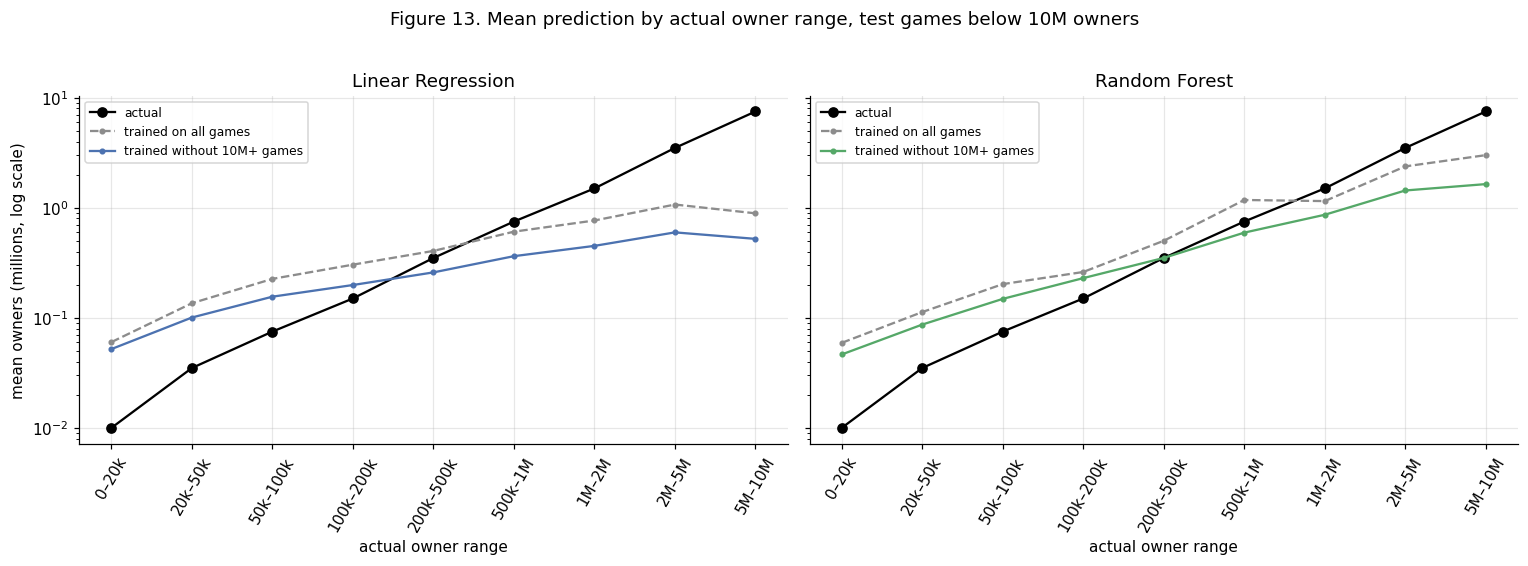

In [8]:
label = "Excluding games with 10M+ owners"
te = test_all[test_all[TARGET] < 10].copy()
order = te.drop_duplicates("estimated_owners").sort_values(TARGET)["estimated_owners"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, name in zip(axes, ["Linear Regression", "Random Forest"]):
    by = pd.DataFrame({"actual": te.groupby("estimated_owners")[TARGET].mean()})
    by["trained on all games"] = pd.Series(fitted[("All games (baseline)", name)].predict(te[FEATURES]), index=te.index) \
        .groupby(te["estimated_owners"]).mean()
    by["trained without 10M+ games"] = pd.Series(fitted[(label, name)].predict(te[FEATURES]), index=te.index) \
        .groupby(te["estimated_owners"]).mean()
    by = by.reindex(order)
    xs = np.arange(len(by))
    ax.plot(xs, by["actual"], color="black", marker="o", label="actual")
    ax.plot(xs, by["trained on all games"].clip(lower=1e-3), color=GREY, marker=".", ls="--", label="trained on all games")
    ax.plot(xs, by["trained without 10M+ games"].clip(lower=1e-3), color=MODEL_COLORS[name], marker=".", label="trained without 10M+ games")
    ax.set_yscale("log")
    ax.set_xticks(xs)
    ax.set_xticklabels([range_label(o) for o in by.index], rotation=60)
    ax.set_xlabel("actual owner range")
    ax.set_title(name)
    ax.legend(fontsize=8)
axes[0].set_ylabel("mean owners (millions, log scale)")
fig.suptitle("Figure 13. Mean prediction by actual owner range, test games below 10M owners", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig13_popular_games_by_range.png"), dpi=150, bbox_inches="tight")
plt.show()

**Interpretation.** Trained without the 10M+ games, both models predict the lower owner ranges more accurately. Random Forest's mean prediction for games with fewer than 20,000 owners falls from about 0.06 to 0.05 million, although this is still about five times the actual 0.01 million. In exchange, games with 1–10 million owners are under-predicted more strongly: for the 5–10M range, Random Forest predicts about 1.7 million, against 3.0 million when trained on all games. Linear Regression stays nearly flat across the ranges (about 0.05 to 0.6 million), which confirms that a linear model on the original owner scale cannot follow a target spanning three orders of magnitude, with or without the popular games.

## 9.8 Findings and decision

**Findings.**
1. **A very small group of games drives the baseline results.** Excluding the 86 games with 10M+ owners (0.11% of games) raises Random Forest's cross-validated R² from 0.01 to 0.23 and Linear Regression's from 0.04 to 0.14, and makes the test results consistent with cross-validation.
2. **The popular games distort the models, not only the metrics.** On the same ordinary games, models trained without them have 25–34% lower MAE.
3. **Excluding more games does not keep helping.** The 1M threshold adds 0.02 R² while removing 1,201 further games; the 100k threshold lowers R² because little variation remains.
4. **Two baseline issues remain.** The default Decision Tree still overfits (negative R² in every scenario), and all models still over-predict the smallest games by a factor of about five, which keeps MAPE in the hundreds of percent.
5. **The features carry real but limited information.** Even in the best scenario, Random Forest explains about a quarter of the variance in owners.

**Decision.** Excluding popular games is kept as a diagnostic result: it confirms that the baseline's poor performance is largely caused by a handful of extreme games. It is not adopted as the main approach, because a game's popularity cannot be known before release, so the exclusion cannot be applied to new games, and because the excluded games are the most commercially important ones. The findings instead point to changing the scale of the target. A logarithmic transformation reduces the influence of the largest games in a similar way (on a log10 scale, 150 million and 10,000 owners become 8.2 and 4.0) without removing any game. This is proposed as the next modification, together with limiting the Decision Tree's depth to address its overfitting.